### Nama: Devina Gusriani
### NIM: 23031554208
### Kelas: 2023B

# Pendahuluan

In [3]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "23031554208")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Terhubung!")

Terhubung!


In [5]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j", 
        )

In [6]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name", name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])
with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


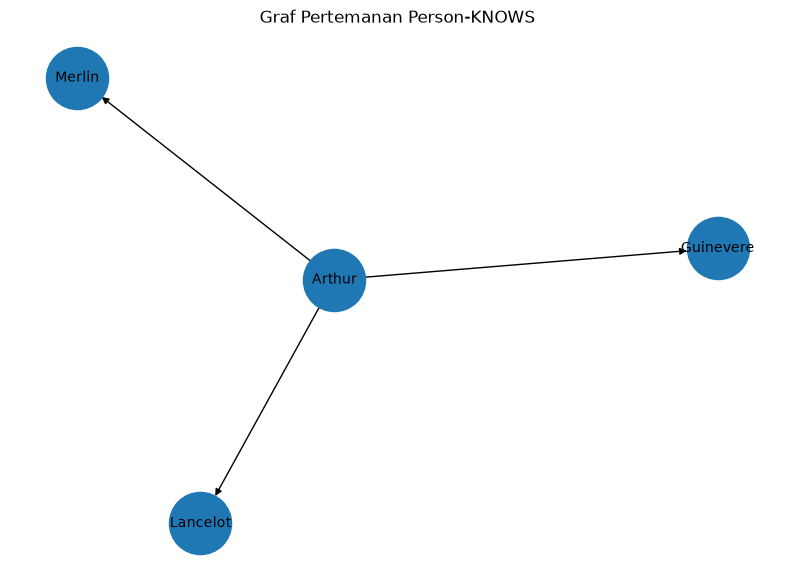

In [7]:
import networkx as nx
import matplotlib.pyplot as plt

# Query untuk mengambil seluruh hubungan pertemanan
query = """
MATCH (a:Person)-[r:KNOWS]->(b:Person)
RETURN a.name AS source,
       b.name AS target
ORDER BY source, target
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    records, _, _ = driver.execute_query(
        query,
        database_="neo4j",
        routing_=RoutingControl.READ
    )

# Membuat directed graph
G = nx.DiGraph()

# Memasukkan node dan edge
for record in records:
    G.add_edge(
        record["source"],
        record["target"]
    )

# Menentukan posisi node
pos = nx.spring_layout(G, seed=42)

# Visualisasi
plt.figure(figsize=(10, 7))

nx.draw_networkx(
    G,
    pos=pos,
    with_labels=True,
    node_size=2000,
    font_size=10,
    arrows=True
)

plt.title("Graf Pertemanan Person-KNOWS")
plt.axis("off")
plt.show()

# Pertanyaan Pendahuluan

### 1. Apa nama database yang digunakan pada tutorial ini?
*Jawab:* Neo4j
### 2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan mengakses database lain dalam 1 instance!
*Jawab:* Database lain dalam satu Neo4j instance dapat diakses menggunakan Neo4j Python Driver dengan parameter 'database_', serta dikelola menggunakan Cypher seperti 'SHOW DATABASES', 'CREATE DATABASE', dan 'DROP DATABASE'
### 3. Apa jenis graf yang dibuat pertemanan ini?
*Jawab:*  Directed graph (graf berarah) dimana Person sebagai node dan 'KNOWS' sebagai relationship berarah

# UTS GRAF SAINS DATA (EDA dan Wrangling)

1. Import dataset dari Kaggle dan menentukan 2 epriode waktu sebagai filter dari data transaksi

In [9]:
import pandas as pd

df = pd.read_csv("data/events.csv")
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

print(df.shape)
print(df.dtypes)
print(df.head())

print(df["event"].value_counts())
print("Visitor unik:", df["visitorid"].nunique())
print("Item unik   :", df["itemid"].nunique())
print("Rentang     :", df["datetime"].min(), "->", df["datetime"].max())

print(df.isna().sum())
print(df.groupby("event")["transactionid"].count())

(2756101, 6)
timestamp                 int64
visitorid                 int64
event                       str
itemid                    int64
transactionid           float64
datetime         datetime64[ms]
dtype: object
       timestamp  visitorid event  itemid  transactionid  \
0  1433221332117     257597  view  355908            NaN   
1  1433224214164     992329  view  248676            NaN   
2  1433221999827     111016  view  318965            NaN   
3  1433221955914     483717  view  253185            NaN   
4  1433221337106     951259  view  367447            NaN   

                 datetime  
0 2015-06-02 05:02:12.117  
1 2015-06-02 05:50:14.164  
2 2015-06-02 05:13:19.827  
3 2015-06-02 05:12:35.914  
4 2015-06-02 05:02:17.106  
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64
Visitor unik: 1407580
Item unik   : 235061
Rentang     : 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
timestamp              0
visitorid   

2. Menerapkan proses filter pada timestamp pada proses persiapan data kemudian menyimpan ke file.csv

In [10]:
# 1. Filter periode (batas akhir inklusif per hari)
mask_p1 = (df["datetime"] >= "2015-06-06") & (df["datetime"] < "2015-08-07")
mask_p2 = (df["datetime"] >= "2015-08-15") & (df["datetime"] < "2015-08-31")

df_p1 = df[mask_p1].copy()
df_p2 = df[mask_p2].copy()

# 2. Jumlah baris dan rentang waktu tiap periode
for nama, d in [("P1", df_p1), ("P2", df_p2)]:
    print(f"{nama}: {len(d):,} baris | "
          f"{d['datetime'].min()} -> {d['datetime'].max()}")

# 3. Komposisi event tiap periode
print(df_p1["event"].value_counts())
print(df_p2["event"].value_counts())

# 4. Visitor dan item unik
print("Visitor P1:", df_p1["visitorid"].nunique())
print("Visitor P2:", df_p2["visitorid"].nunique())
print("Item P1   :", df_p1["itemid"].nunique())
print("Item P2   :", df_p2["itemid"].nunique())

# 5. Irisan: visitor yang ada di P1 dan P2
visitor_both = set(df_p1["visitorid"]) & set(df_p2["visitorid"])
print("Visitor di P1 & P2:", len(visitor_both))

# 6. Item di P2 yang tidak pernah muncul di P1
item_baru = set(df_p2["itemid"]) - set(df_p1["itemid"])
print("Item P2 yang tidak ada di P1:", len(item_baru))

P1: 1,308,161 baris | 2015-06-06 00:00:00.445000 -> 2015-08-06 23:59:57.486000
P2: 282,649 baris | 2015-08-15 00:00:07.484000 -> 2015-08-30 23:59:52.674000
event
view           1264487
addtocart        32838
transaction      10836
Name: count, dtype: int64
event
view           272523
addtocart        7668
transaction      2458
Name: count, dtype: int64
Visitor P1: 681322
Visitor P2: 160824
Item P1   : 170194
Item P2   : 78501
Visitor di P1 & P2: 10147
Item P2 yang tidak ada di P1: 16833


3. Menyimpan dataset yang akan digunakan

In [11]:
kolom_asli = ["timestamp", "visitorid", "event", "itemid", "transactionid"]

df_p1[kolom_asli].to_csv("data/events_p1.csv", index=False)
df_p2[kolom_asli].to_csv("data/events_p2.csv", index=False)

In [12]:
import os

for f in ["data/events_p1.csv", "data/events_p2.csv"]:
    cek = pd.read_csv(f)
    print(f, cek.shape, f"{os.path.getsize(f)/1e6:.1f} MB")

data/events_p1.csv (1308161, 5) 46.1 MB
data/events_p2.csv (282649, 5) 10.0 MB


4. Mengosongkan instance sebelum digunakan

In [13]:
from neo4j import GraphDatabase
from tqdm.auto import tqdm

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "23031554208")

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

In [14]:
driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")
records, _, _ = driver.execute_query(
    "MATCH (n) RETURN count(n) AS jumlah", database_="neo4j"
)
print(records[0]["jumlah"])   # harus 0

0


In [15]:
with driver.session(database="neo4j") as session:
    result = session.run("RETURN 1 AS angka")
    print("Hasil session:", result.single()["angka"])

Hasil session: 1


5. EDA data P1 (training) dan P2 (test)

In [17]:
P1_PATH = "data/events_p1.csv"
P2_PATH = "data/events_p2.csv"
p1_sample = pd.read_csv(P1_PATH, nrows=5)
p2_sample = pd.read_csv(P2_PATH, nrows=5)
print("Display P1:")
display(p1_sample)
print("\nDisplay P2:")
display(p2_sample)

Display P1:


,timestamp,visitorid,event,itemid,transactionid
0,1433569064254,896988,view,96581,NaN
1,1433570256041,872999,view,431632,NaN
2,1433570392312,1076434,view,457407,NaN
3,1433569461293,1332584,view,64537,NaN
4,1433569765347,155943,view,105149,NaN



Display P2:


,timestamp,visitorid,event,itemid,transactionid
0,1439596906728,483641,view,184331,NaN
1,1439596936993,973525,view,102471,NaN
2,1439596891810,483641,view,383662,NaN
3,1439596889298,783404,view,461538,NaN
4,1439596918377,1164158,view,141157,NaN


a. Jumlah baris pada dataset

In [18]:
def count_csv_rows(path):
    with open(path, "r", encoding="utf-8") as f:
        return sum(1 for _ in f) - 1

p1_rows = count_csv_rows(P1_PATH)
p2_rows = count_csv_rows(P2_PATH)

print("Jumlah baris P1:", p1_rows)
print("Jumlah baris P2:", p2_rows)

Jumlah baris P1: 1308161
Jumlah baris P2: 282649


## Import dataset P1 (training) ke Neo4j

a. Membuat constraint (memastikan visitorId dan itemId bernilai unique)

In [19]:
with driver.session(database="neo4j") as session:
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """)
    
    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """)

print("Constraint berhasil dibuat.")

Constraint berhasil dibuat.


b. Import dataset

In [20]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {
        visitorId: row.visitorid
    })

    MERGE (i:Item {
        itemId: row.itemid
    })

    FOREACH (_ IN CASE
        WHEN row.event = 'view' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:VIEWED {
            timestamp: row.timestamp
        }]->(i)
    )

    FOREACH (_ IN CASE
        WHEN row.event = 'addtocart' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:ADDED_TO_CART {
            timestamp: row.timestamp
        }]->(i)
    )

    FOREACH (_ IN CASE
        WHEN row.event = 'transaction' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    )

    RETURN count(*) AS processed
    """

    result = tx.run(
        cypher_query,
        batch=batch
    )

    return result.single()["processed"]


In [21]:
def import_csv_to_neo4j(csv_path, batch_size=5000):
    print(f"Mulai import: {csv_path}")
    
    total_rows = count_csv_rows(csv_path)
    chunks = pd.read_csv(
        csv_path,
        chunksize=batch_size
    )

    total_processed = 0

    with driver.session(database="neo4j") as session:

        for chunk in tqdm(
            chunks,
            total=(total_rows + batch_size - 1) // batch_size,
            desc=f"Import {os.path.basename(csv_path)}"
        ):
            # Bersihkan transactionid
            chunk["transactionid"] = (
                chunk["transactionid"]
                .fillna("")
                .astype(str)
            )
            # Pastikan tipe ID konsisten
            chunk["visitorid"] = chunk["visitorid"].astype(int)
            chunk["itemid"] = chunk["itemid"].astype(int)
            chunk["timestamp"] = chunk["timestamp"].astype(int)
            records = chunk.to_dict(
                orient="records"
            )
            processed = session.execute_write(
                import_batch,
                records
            )
            total_processed += processed
    print(
        f"Selesai. Total row diproses: {total_processed}"
    )

In [22]:
import_csv_to_neo4j(
    P1_PATH,
    batch_size=5000
)

Mulai import: data/events_p1.csv


Import events_p1.csv:   0%|          | 0/262 [00:00<?, ?it/s]

Selesai. Total row diproses: 1308161


c. Komposisi subgraphs yang telah dibuat

Cypher digunakan untuk mengambil *subgraph* yang terdiri atas simpul `Visitor` dan `Item` beserta interaksi di antara keduanya. Klausa `MATCH (v:Visitor)-[r]->(i:Item)` mencari pola hubungan berarah dari `Visitor` menuju `Item`, sedangkan `WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']` membatasi hubungan yang digunakan hanya pada tiga jenis interaksi tersebut. Selanjutnya, `RETURN` mengambil `visitorId`, `itemId`, dan tipe interaksi untuk setiap hubungan dengan `LIMIT 100` untuk membatasi *subgraph* hingga maksimal 100 *record*. Hasil query dieksekusi melalui **Neo4j** kemudian digunakan untuk membentuk `DiGraph` pada **NetworkX**. Setiap `Visitor` dan `Item` ditambahkan sebagai simpul dengan atribut `node_type`, sedangkan interaksinya menjadi *edge*. Komposisi *subgraph* kemudian dihitung menggunakan **Python** dengan menghitung jumlah bertipe `Visitor`, jumlah simpul bertipe `Item`, serta jumlah *edge* yang terbentuk.

Jumlah Visitor: 68
Jumlah Item: 4
Jumlah edge: 68


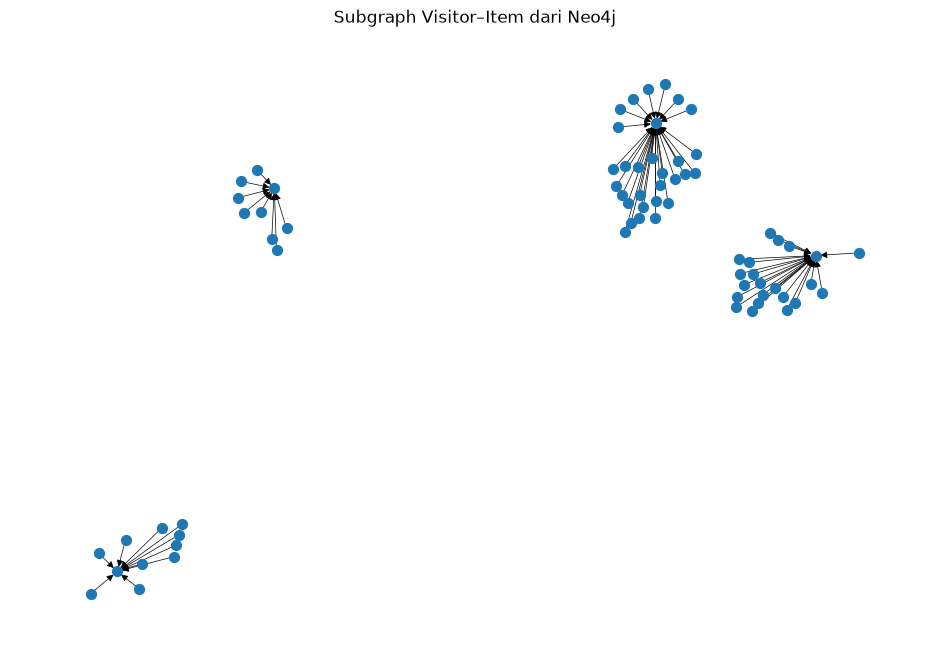

In [26]:
import networkx as nx
import matplotlib.pyplot as plt

query_subgraph = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN v.visitorId AS visitorid,
       i.itemId AS itemid,
       type(r) AS interaction
LIMIT 100
"""

records, _, _ = driver.execute_query(query_subgraph, database_="neo4j")
G = nx.DiGraph()

for record in records:
    visitor = f"V_{record['visitorid']}"
    item = f"I_{record['itemid']}"
    G.add_node(visitor, node_type="Visitor")
    G.add_node(item, node_type="Item")
    G.add_edge(visitor, item, interaction=record["interaction"])

print("Jumlah Visitor:", sum(1 for n in G.nodes if G.nodes[n]["node_type"] == "Visitor"))
print("Jumlah Item:", sum(1 for n in G.nodes if G.nodes[n]["node_type"] == "Item"))
print("Jumlah edge:", G.number_of_edges())
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G,seed=42)

nx.draw_networkx(G, pos=pos, with_labels=False, node_size=50, width=0.5, arrows=True)
plt.title("Subgraph Visitor–Item dari Neo4j")
plt.axis("off")
plt.show()

d. Jumlah node dan jumlah relationship yang sudah dibuat

In [ ]:
query_summary = """
CALL {
    MATCH (n)
    RETURN count(n) AS total_simpul
}
CALL {
    MATCH ()-[r]->()
    RETURN count(r) AS total_relasi
}
RETURN total_simpul, total_relasi
"""
result = driver.execute_query(query_summary,database_="neo4j")
df_summary = pd.DataFrame([record.data() for record in result.records])
display(df_summary)

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL () { ... }', position=<SummaryInputPosition line=2, column=1, offset=1>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 1, 'line': 2, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nCALL {\n    MATCH (n)\n    RETURN count(n) AS total_simpul\n}\nCALL {\n    MATCH ()-[r]->()\n    RETURN count(r) AS total_relasi\n}\nRETURN total_simpul, total_relasi\n'
Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is dep

,total_simpul,total_relasi
0,851516,1308161


e. Jumlah relationship yang sudah di-import

In [28]:
records, _, _ = driver.execute_query(
    """
    MATCH ()-[r]->()
    RETURN type(r) AS tipe, count(*) AS jumlah
    ORDER BY tipe
    """,
    database_="neo4j"
)

for record in records:
    print(record["tipe"], record["jumlah"])

ADDED_TO_CART 32838
BOUGHT 10836
VIEWED 1264487


f. Jumlah node yang sudah di-import

In [29]:
records, _, _ = driver.execute_query(
    """
    MATCH (n)
    RETURN labels(n) AS label, count(*) AS jumlah
    ORDER BY label
    """,
    database_="neo4j"
)

for record in records:
    print(record["label"], record["jumlah"])

['Item'] 170194
['Visitor'] 681322


## Tahap VSM untuk simpul yang diasumsikan sebagai user

a. Menghitung VSM untuk user

In [34]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

p1 = pd.read_csv(P1_PATH)
event_weight = {"view": 1.0, "addtocart": 3.0, "transaction": 5.0}
p1["weight"] = p1["event"].map(event_weight)
p1 = p1.dropna(subset=["weight"]).copy()

# Satu nilai interaksi untuk setiap pasangan visitor-item
interactions = (p1.groupby(["visitorid", "itemid"])["weight"].max().reset_index())

# User sebagai baris
# Item sebagai fitur/kolom
user_ids = np.sort(interactions["visitorid"].unique())
item_ids = np.sort(interactions["itemid"].unique())
user_to_idx = {user_id: idx for idx, user_id in enumerate(user_ids)}
item_to_idx = {item_id: idx for idx, item_id in enumerate(item_ids)}
rows = interactions["visitorid"].map(user_to_idx).to_numpy()
cols = interactions["itemid"].map(item_to_idx).to_numpy()
values = interactions["weight"].to_numpy(dtype=np.float32)

X_user = csr_matrix(
    (values, (rows, cols)),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.float32
)

def describe_user_vsm(X):
    total_cells = X.shape[0] * X.shape[1]
    sparsity = 1 - X.nnz / total_cells
    user_degree = np.diff(X.indptr)

    print("=== KARAKTERISTIK USER VSM ===")
    print("Dimensi matriks       :", X.ndim)
    print("Shape                 :", X.shape)
    print("Jumlah user           :", X.shape[0])
    print("Jumlah fitur/item     :", X.shape[1])
    print("Jumlah sel non-zero   :", X.nnz) #Komponen graf yang memiliki nilai atau bobot tidak sama dengan nol
describe_user_vsm(X_user)

=== KARAKTERISTIK USER VSM ===
Dimensi matriks       : 2
Shape                 : (681322, 170194)
Jumlah user           : 681322
Jumlah fitur/item     : 170194
Jumlah sel non-zero   : 1021292


b. Melakukan user projection (melihat visitor yang berinteraksi dengan item yang sama dengan mengambil 50 user paling aktif)

User Projection
Jumlah node: 50
Jumlah edge: 1145
Density: 0.9346938775510204


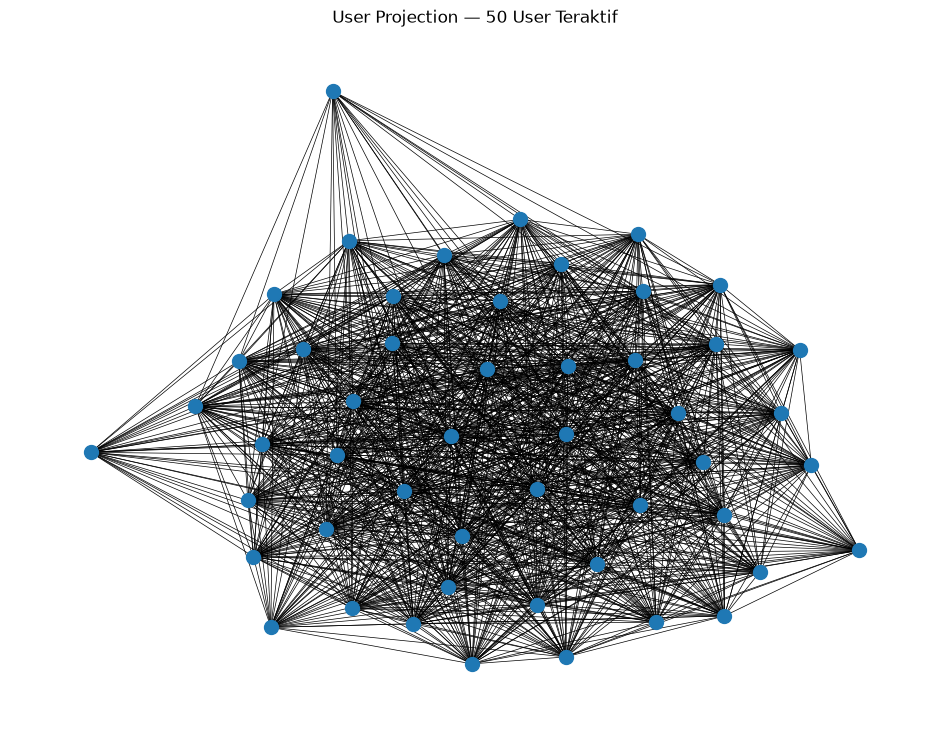

In [ ]:
top_users = (interactions.groupby("visitorid").size().nlargest(50).index)
user_sample = X_user[[user_to_idx[u] for u in top_users]]

# Hitung cosine similarity
from sklearn.preprocessing import normalize
user_sample_norm = normalize(user_sample,norm="l2")
similarity_matrix = (user_sample_norm @ user_sample_norm.T).toarray()
G_user = nx.Graph()

for i, user_a in enumerate(top_users):
    G_user.add_node(f"U_{user_a}")

for i in range(len(top_users)):
    for j in range(i + 1, len(top_users)):

        sim = similarity_matrix[i, j]

        if sim > 0:
            G_user.add_edge(
                f"U_{top_users[i]}",
                f"U_{top_users[j]}",
                similarity=float(sim)
            )

print("User Projection")
print("Jumlah node:", G_user.number_of_nodes())
print("Jumlah edge:", G_user.number_of_edges())
print("Density:", nx.density(G_user))
plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G_user, seed=42)
nx.draw_networkx(G_user, pos=pos, with_labels=False, node_size=100, width=0.5)
plt.title("User Projection — 50 User Teraktif")
plt.axis("off")
plt.show()

## Tahap VSM simpul yang diasumsikan sebagai Item

a. Menghitung VSM untuk Item (yang merupakan transpose dari User VSM)

In [39]:
X_item = X_user.T.tocsr()
def describe_item_vsm(X):
    total_cells = X.shape[0] * X.shape[1]
    sparsity = 1 - X.nnz / total_cells

    item_degree = np.diff(X.indptr)

    print("=== KARAKTERISTIK ITEM VSM ===")
    print("Dimensi matriks       :", X.ndim)
    print("Shape                 :", X.shape)
    print("Jumlah item           :", X.shape[0])
    print("Jumlah fitur/user     :", X.shape[1])
    print("Nilai nonzero         :", X.nnz)
describe_item_vsm(X_item)

=== KARAKTERISTIK ITEM VSM ===
Dimensi matriks       : 2
Shape                 : (170194, 681322)
Jumlah item           : 170194
Jumlah fitur/user     : 681322
Nilai nonzero         : 1021292


b. Menampilkan item dengan jumlah interaksi terbanyak

In [44]:
item_interaction_count = (interactions.groupby("itemid").size())
top_item_stats = (item_interaction_count.sort_values(ascending=False).head(5))
display(top_item_stats.to_frame("jumlah_interaksi"))

,jumlah_interaksi
itemid,
5411,1677
219512,676
309778,662
370653,624
461686,600


=== ITEM PROJECTION ===
Jumlah node: 50
Jumlah edge: 627
Density: 0.5118367346938776


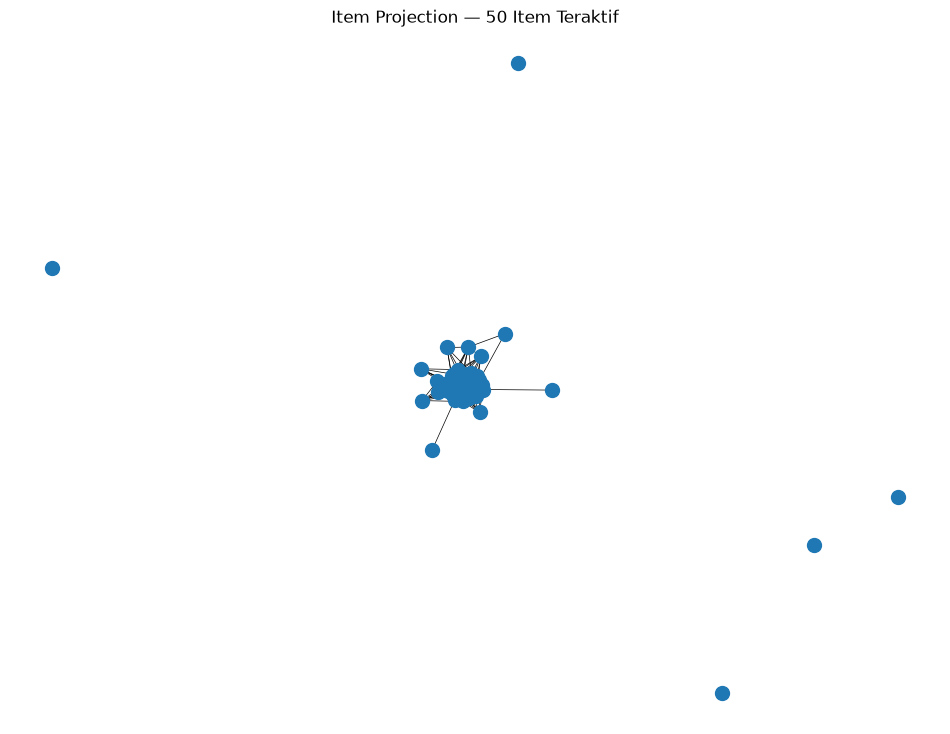

In [46]:
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize

# Ambil 50 item dengan jumlah interaksi terbanyak
top_items = (
    interactions
    .groupby("itemid")
    .size()
    .nlargest(50)
    .index
)

# Ambil baris matriks yang mewakili 50 item tersebut
item_sample = X_item[
    [item_to_idx[item_id] for item_id in top_items]
]

# Normalisasi vektor item
item_sample_norm = normalize(item_sample, norm="l2")

# Hitung cosine similarity antar-item
similarity_matrix_item = (
    item_sample_norm @ item_sample_norm.T
).toarray()

# Bentuk graf Item Projection
G_item = nx.Graph()

for item_id in top_items:
    G_item.add_node(f"I_{item_id}")

for i in range(len(top_items)):
    for j in range(i + 1, len(top_items)):
        sim = similarity_matrix_item[i, j]

        if sim > 0:
            G_item.add_edge(
                f"I_{top_items[i]}",
                f"I_{top_items[j]}",
                similarity=float(sim)
            )

print("=== ITEM PROJECTION ===")
print("Jumlah node:", G_item.number_of_nodes())
print("Jumlah edge:", G_item.number_of_edges())
print("Density:", nx.density(G_item))

# Visualisasi
plt.figure(figsize=(12, 9))

pos = nx.spring_layout(G_item, seed=42)

nx.draw_networkx(
    G_item,
    pos=pos,
    with_labels=False,
    node_size=100,
    width=0.5
)

plt.title("Item Projection — 50 Item Teraktif")
plt.axis("off")
plt.show()

## Perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

Memilih Item Projection karena memertimbangkan dari segi efisiensi komputasi berdasarkan jumlah entitas yang lebih sedikit daripada user projection. Item projection hanya melibatkan 170.194 item dibandingkan dengan 681.322 user. Jumlah apsangan unik yang mungkin dibandingkan juga sekitas 16 kali lebih sedikit.

a. Menghitung similarity untuk Item Projection menggunakan python

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import normalize

# Memilih item dengan interaksi terbanyak sebagai anchor
top_items = interactions.groupby("itemid").size().nlargest(50).index
anchor_item = int(top_items[0])

# Normalisasi seluruh vektor item
X_item_norm = normalize(X_item, norm="l2", axis=1)

# Mencari indeks item acuan
anchor_idx = item_to_idx[anchor_item]

# Menghitung similarity anchor terhadap seluruh item
similarities = (
    X_item_norm[anchor_idx] @ X_item_norm.T
).toarray().ravel()

# Mengeluarkan item acuan dari hasil
similarities[anchor_idx] = -1

# Mengambil 5 item dengan similarity tertinggi
top_idx = np.argsort(similarities)[::-1]
top_idx = [idx for idx in top_idx if similarities[idx] > 0][:5]

similarity_item_df = pd.DataFrame({
    "itemid": item_ids[top_idx].astype(int),
    "similarity": similarities[top_idx]
})

print("Anchor item:", anchor_item)
display(similarity_item_df)

Anchor item: 5411


,itemid,similarity
0,33030,0.153266
1,33956,0.092528
2,358234,0.080041
3,37807,0.075379
4,375492,0.064783


b. Menyimpan similarity ke graf Neo4j

In [48]:
similarity_records = similarity_item_df.to_dict("records")

query_save = """
MATCH (anchor:Item {itemId: $anchor_item})
UNWIND $neighbors AS neighbor
MATCH (item:Item {itemId: neighbor.itemid})
MERGE (anchor)-[r:SIMILAR_TO]->(item)
SET r.similarity = neighbor.similarity
RETURN
    anchor.itemId AS anchor_item,
    item.itemId AS similar_item,
    r.similarity AS similarity
ORDER BY similarity DESC
"""
records, summary, keys = driver.execute_query(query_save, anchor_item=anchor_item, neighbors=similarity_records, database_="neo4j")

for record in records:
    print(record)

<Record anchor_item=5411 similar_item=33030 similarity=0.15326635539531708>
<Record anchor_item=5411 similar_item=33956 similarity=0.0925280898809433>
<Record anchor_item=5411 similar_item=358234 similarity=0.08004074543714523>
<Record anchor_item=5411 similar_item=37807 similarity=0.07537945359945297>
<Record anchor_item=5411 similar_item=375492 similarity=0.06478262692689896>


c. Cypher untuk mendapatkan lima similarity tertinggi

In [49]:
records, _, _ = driver.execute_query(
    """
    MATCH (anchor:Item {itemId: $anchor_item})
          -[r:SIMILAR_TO]->(item:Item)
    RETURN
        anchor.itemId AS anchor_item,
        item.itemId AS similar_item,
        r.similarity AS similarity
    ORDER BY similarity DESC
    LIMIT 5
    """,
    anchor_item=anchor_item,
    database_="neo4j"
)

for record in records:
    print(record)

<Record anchor_item=5411 similar_item=33030 similarity=0.15326635539531708>
<Record anchor_item=5411 similar_item=33956 similarity=0.0925280898809433>
<Record anchor_item=5411 similar_item=358234 similarity=0.08004074543714523>
<Record anchor_item=5411 similar_item=37807 similarity=0.07537945359945297>
<Record anchor_item=5411 similar_item=375492 similarity=0.06478262692689896>


```cypher
d. Cypher SQL untuk memperlihatkan kondisi sebelum perhitungan similarity
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN v, r, i
LIMIT 50
```

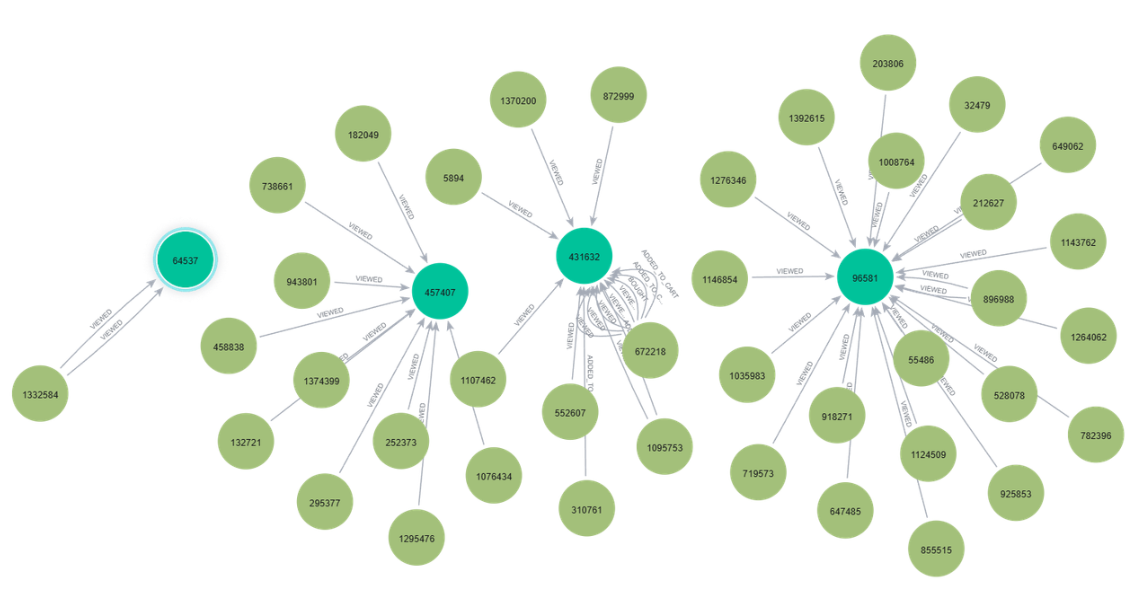

e. Kondisi setelah dilakukan similarity

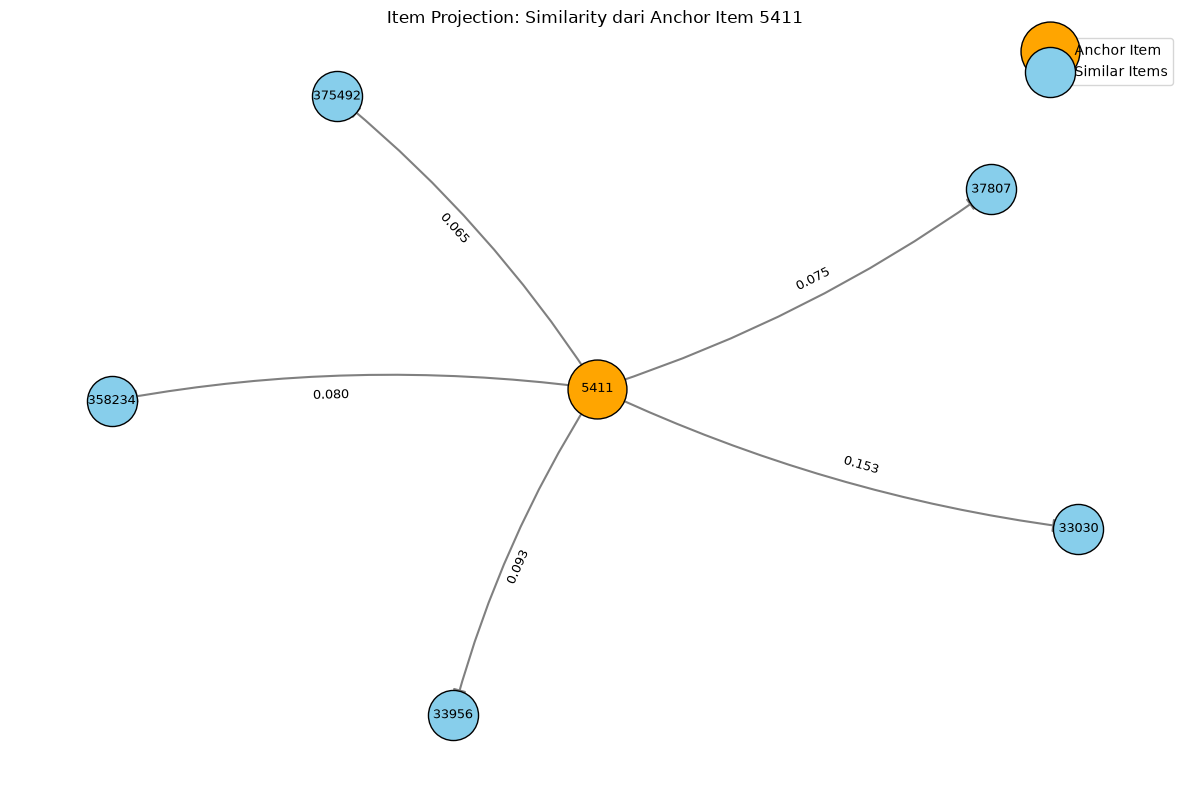

Jumlah node: 6
Jumlah relasi: 5


In [50]:
import networkx as nx
import matplotlib.pyplot as plt

# Membuat graf dari hasil query Neo4j
G = nx.DiGraph()

for record in records:
    anchor = record["anchor_item"]
    similar_item = record["similar_item"]
    similarity = record["similarity"]

    G.add_node(anchor, node_type="Anchor")
    G.add_node(similar_item, node_type="Similar Item")
    G.add_edge(
        anchor,
        similar_item,
        similarity=similarity
    )

# Menentukan posisi node
pos = nx.spring_layout(G, seed=42)

# Membedakan node anchor dan item yang mirip
anchor_nodes = [
    node for node, data in G.nodes(data=True)
    if data["node_type"] == "Anchor"
]
similar_nodes = [
    node for node, data in G.nodes(data=True)
    if data["node_type"] == "Similar Item"
]

plt.figure(figsize=(12, 8))

nx.draw_networkx_nodes(
    G, pos,
    nodelist=anchor_nodes,
    node_size=1800,
    node_color="orange",
    edgecolors="black",
    label="Anchor Item"
)

nx.draw_networkx_nodes(
    G, pos,
    nodelist=similar_nodes,
    node_size=1300,
    node_color="skyblue",
    edgecolors="black",
    label="Similar Items"
)

nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowsize=20,
    width=1.5,
    edge_color="gray",
    connectionstyle="arc3,rad=0.08"
)

# Label node menggunakan ID item
nx.draw_networkx_labels(
    G, pos,
    labels={node: str(node) for node in G.nodes()},
    font_size=9
)

# Label edge menggunakan nilai similarity
edge_labels = {
    (u, v): f"{data['similarity']:.3f}"
    for u, v, data in G.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=9,
    label_pos=0.55
)

plt.title(f"Item Projection: Similarity dari Anchor Item {anchor_item}")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah node:", G.number_of_nodes())
print("Jumlah relasi:", G.number_of_edges())

# UTS Graf Sains Data (Analytics)

a. Memilih user secara acak dan reproducible

In [51]:
import numpy as np
import pandas as pd

# P1 sudah digunakan sebagai data training
# Baca P2 sebagai data testing
p2_eval = pd.read_csv(P2_PATH)

# Cari user yang ada pada P1 dan P2
p1_users = set(p1["visitorid"].unique())
p2_users = set(p2_eval["visitorid"].unique())

common_users = np.array(sorted(p1_users & p2_users))

# Pemilihan acak yang dapat direproduksi
rng = np.random.default_rng(42)
anchor_user = int(rng.choice(common_users))

print("Jumlah user yang muncul di P1 dan P2:", len(common_users))
print("User terpilih:", anchor_user)

Jumlah user yang muncul di P1 dan P2: 10147
User terpilih: 121975


b. Menentukan lima tetangga terdekat menggunakan KNN

In [52]:
from sklearn.preprocessing import normalize

# Normalisasi User VSM dari P1
X_user_norm = normalize(X_user, norm="l2", axis=1)

# Indeks user target dalam matriks
anchor_idx = user_to_idx[anchor_user]

# Hitung similarity user target dengan seluruh user
similarities = (
    X_user_norm[anchor_idx] @ X_user_norm.T
).toarray().ravel()

# Keluarkan user target dari kandidat tetangga
similarities[anchor_idx] = -1

# Ambil 5 tetangga terdekat
top_neighbor_idx = np.argsort(similarities)[::-1][:5]

similarity_df = pd.DataFrame({
    "visitorid": user_ids[top_neighbor_idx],
    "similarity": similarities[top_neighbor_idx]
})

print("Lima tetangga terdekat:")
display(similarity_df)

Lima tetangga terdekat:


,visitorid,similarity
0,846151,0.654654
1,635928,0.534522
2,285388,0.455842
3,1249098,0.455842
4,1336933,0.436436


c. Menghasilkan rekomendasi item

In [53]:
# Indeks kelima tetangga pada User VSM
neighbor_ids = similarity_df["visitorid"].to_numpy(dtype=np.int64)
neighbor_similarities = similarity_df["similarity"].to_numpy(dtype=np.float32)

neighbor_indices = np.array(
    [user_to_idx[int(uid)] for uid in neighbor_ids],
    dtype=int
)

# Matriks interaksi lima tetangga
neighbor_matrix = X_user[neighbor_indices]

# Skor item = jumlah bobot interaksi tetangga x similarity tetangga
scores = np.asarray(
    neighbor_matrix.T.dot(neighbor_similarities)
).ravel()

# Keluarkan item yang sudah pernah diinteraksikan user target pada P1
seen_item_indices = X_user[anchor_idx].indices
scores[seen_item_indices] = 0.0

# Ambil lima rekomendasi dengan skor positif tertinggi
ranked_indices = np.argsort(scores)[::-1]
top_indices = [
    idx for idx in ranked_indices
    if scores[idx] > 0
][:5]

recommendations = pd.DataFrame({
    "itemid": item_ids[top_indices],
    "score": scores[top_indices]
})

recommendations.insert(0, "rank", range(1, len(recommendations) + 1))

print("Lima item rekomendasi untuk user:", anchor_user)
display(recommendations)

Lima item rekomendasi untuk user: 121975


,rank,itemid,score
0,1,275361,0.455842
1,2,403969,0.455842
2,3,98728,0.455842
3,4,89522,0.455842
4,5,89250,0.455842


d. Menentukan tiga item yang diiklankan

In [54]:
top3_ads = recommendations.head(3).copy()

print("Tiga item yang diiklankan:")
display(top3_ads)

Tiga item yang diiklankan:


,rank,itemid,score
0,1,275361,0.455842
1,2,403969,0.455842
2,3,98728,0.455842


e. Menyiapkan ground truth dari P2

In [55]:
# Bobot relevansi untuk data testing P2
test_relevance_weight = {
    "view": 1,
    "addtocart": 2,
    "transaction": 3
}

p2_eval["relevance"] = p2_eval["event"].map(test_relevance_weight)

# Ambil interaksi user target di P2
user_test = p2_eval[
    (p2_eval["visitorid"] == anchor_user) &
    (p2_eval["relevance"].notna())
].copy()

# Evaluasi hanya item yang ada dalam katalog P1
known_items = set(map(int, item_ids))
user_test["itemid"] = user_test["itemid"].astype(int)

user_test = user_test[user_test["itemid"].isin(known_items)]

# Jangan anggap item yang sudah pernah dilihat di P1 sebagai rekomendasi baru
seen_item_ids = set(
    map(int, item_ids[X_user[anchor_idx].indices])
)
user_test = user_test[~user_test["itemid"].isin(seen_item_ids)]

# Jika sebuah item memiliki beberapa jenis interaksi,
# gunakan tingkat relevansi tertinggi
ground_truth = (
    user_test.groupby("itemid")["relevance"]
    .max()
    .to_dict()
)

print("Jumlah item relevan di P2:", len(ground_truth))
print("Ground truth (itemid: relevance):")
print(ground_truth)

Jumlah item relevan di P2: 3
Ground truth (itemid: relevance):
{83825: 1, 177133: 1, 324974: 1}


f. Menghitung Hit@5 dan NDCG@5

In [56]:
recommended_items = (
    recommendations["itemid"].astype(int).tolist()[:5]
)

# Hit@5 = 1 jika minimal satu item rekomendasi relevan
hits = [
    1 if item in ground_truth else 0
    for item in recommended_items
]

hit_at_5 = int(any(hits))

print("Rekomendasi Top-5:", recommended_items)
print("Indikator relevansi:", hits)
print("Hit@5:", hit_at_5)

Rekomendasi Top-5: [275361, 403969, 98728, 89522, 89250]
Indikator relevansi: [0, 0, 0, 0, 0]
Hit@5: 0


In [57]:
# Relevansi setiap item sesuai urutan rekomendasi
relevance_scores = [
    ground_truth.get(item, 0)
    for item in recommended_items
]

# Hitung DCG@5
dcg_at_5 = sum(
    (2**rel - 1) / np.log2(rank + 2)
    for rank, rel in enumerate(relevance_scores)
)

# Susun relevansi ideal dari yang tertinggi
ideal_relevance = sorted(
    ground_truth.values(),
    reverse=True
)[:5]

# Hitung IDCG@5
idcg_at_5 = sum(
    (2**rel - 1) / np.log2(rank + 2)
    for rank, rel in enumerate(ideal_relevance)
)

# Hitung NDCG@5
ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else np.nan
)

print("Relevansi rekomendasi:", relevance_scores)
print("DCG@5:", round(dcg_at_5, 4))
print("IDCG@5:", round(idcg_at_5, 4))
print("NDCG@5:", round(ndcg_at_5, 4)
      if not np.isnan(ndcg_at_5) else "Tidak terdefinisi")

Relevansi rekomendasi: [0, 0, 0, 0, 0]
DCG@5: 0.0
IDCG@5: 2.1309
NDCG@5: 0.0
